# 1. Load the benchmark dataset using Pandas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
import seaborn as sns

### Basic dataset checks:

In [2]:
df = pd.read_csv("iris.csv")
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [3]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
df.shape

(150, 5)

In [5]:
df.columns

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')

In [6]:
df.select_dtypes(exclude='number')

,species
0,setosa
1,setosa
2,setosa
3,setosa
4,setosa
...,...
145,virginica
146,virginica
147,virginica
148,virginica


In [7]:
df.select_dtypes(include='number')

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [8]:
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [10]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


# . EDA - Perform exploratory pairplots with Seaborn

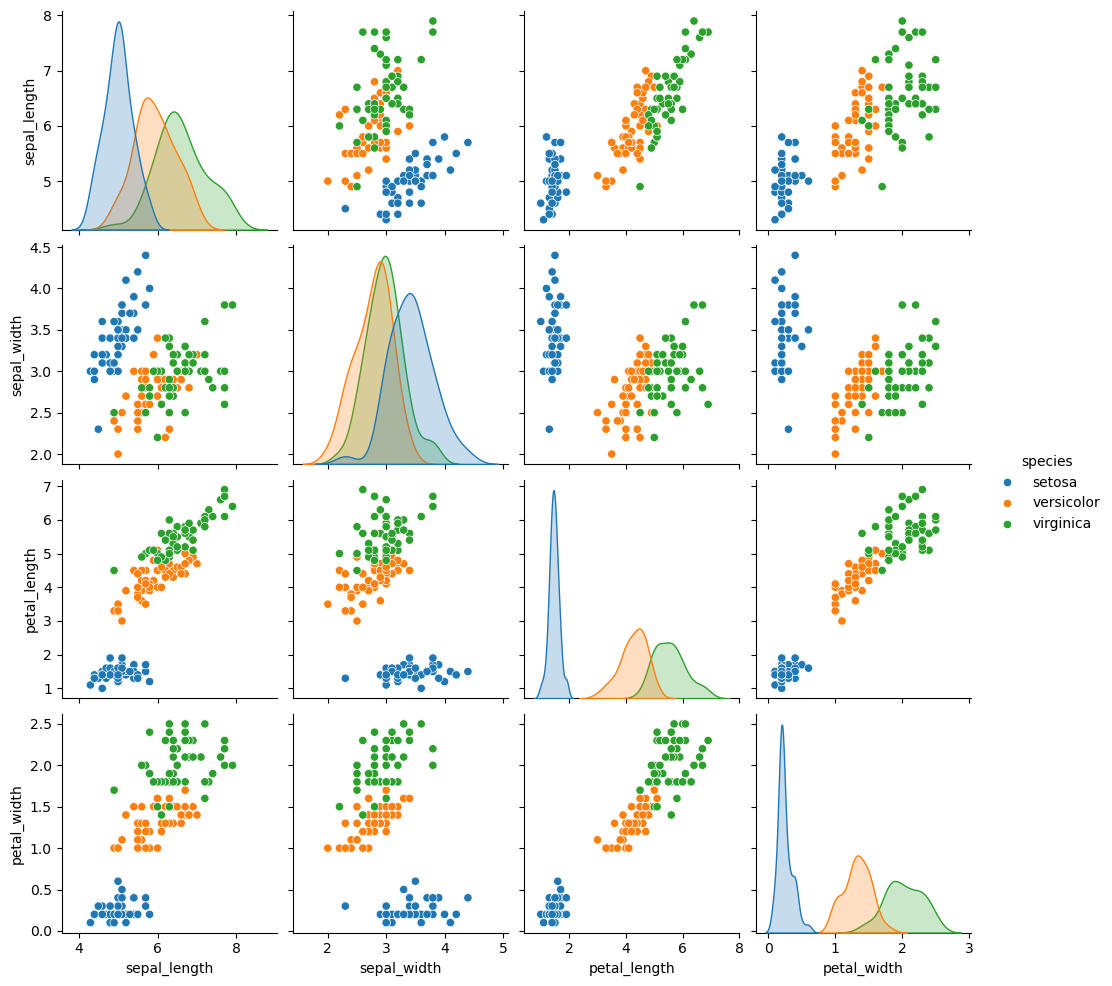

In [11]:
sns.pairplot(df, hue="species")
plt.show()

# 3. Normalize features using StandardScaler()

### Separate X and y

In [12]:
x = df[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']]
y = df['species']

In [13]:
x

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [14]:
y

0         setosa
1         setosa
2         setosa
3         setosa
4         setosa
         ...    
145    virginica
146    virginica
147    virginica
148    virginica
149    virginica
Name: species, Length: 150, dtype: object

### Train/Test Split (80/20)

In [15]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [16]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(120, 4)
(30, 4)
(120,)
(30,)


### StandardScaler

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [18]:
print(x_train_scaled.shape)
print(x_test_scaled.shape)

(120, 4)
(30, 4)


### Verify scaling

In [19]:
print("Before Scaling:")
print(x_train.mean())
print(x_train.std())

print("\nAfter Scaling:")
print(x_train_scaled.mean(axis=0))
print(x_train_scaled.std(axis=0))

Before Scaling:
sepal_length    5.841667
sepal_width     3.048333
petal_length    3.770000
petal_width     1.205000
dtype: float64
sepal_length    0.840926
sepal_width     0.448524
petal_length    1.768520
petal_width     0.762663
dtype: float64

After Scaling:
[-1.36927506e-16  9.99200722e-16  1.66533454e-17  1.70234197e-16]
[1. 1. 1. 1.]


In [20]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


# 4. Train LogisticRegression and DecisionTreeClassifier

### Logistic Regression

In [21]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(x_train_scaled, y_train)
y_pred_lr = lr.predict(x_test_scaled)

### Decision Tree

In [22]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(x_train, y_train)
y_pred_dt = dt.predict(x_test)

### Evaluate both models

In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [24]:
print("Logistic Regression")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, average='macro'))
print("Recall:", recall_score(y_test, y_pred_lr, average='macro'))
print("F1 Score:", f1_score(y_test, y_pred_lr, average='macro'))

Logistic Regression
Accuracy: 0.9333333333333333
Precision: 0.9333333333333332
Recall: 0.9333333333333332
F1 Score: 0.9333333333333332


In [25]:
print("Decision Tree")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt, average='macro'))
print("Recall:", recall_score(y_test, y_pred_dt, average='macro'))
print("F1 Score:", f1_score(y_test, y_pred_dt, average='macro'))

Decision Tree
Accuracy: 0.9333333333333333
Precision: 0.9333333333333332
Recall: 0.9333333333333332
F1 Score: 0.9333333333333332


In [26]:
print("Logistic Regression:", y_pred_lr)
print("Decision Tree:", y_pred_dt)

Logistic Regression: ['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']
Decision Tree: ['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


In [27]:
print((y_pred_lr == y_pred_dt).sum())

30


# 5. Plot the confusion matrix heatmap and plot the decision boundary visualization.

In [28]:
from sklearn.metrics import confusion_matrix

class_names = ['setosa', 'versicolor', 'virginica']

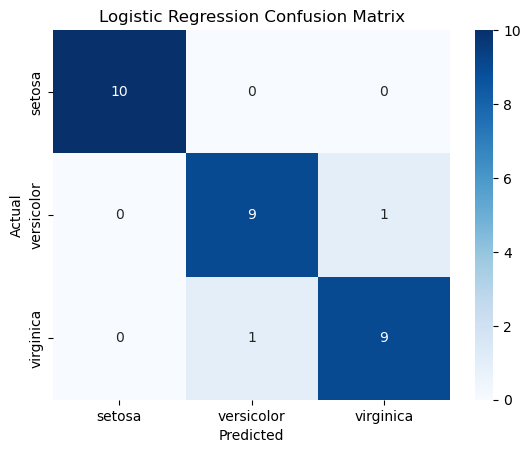

In [29]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues',xticklabels=class_names,yticklabels=class_names)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

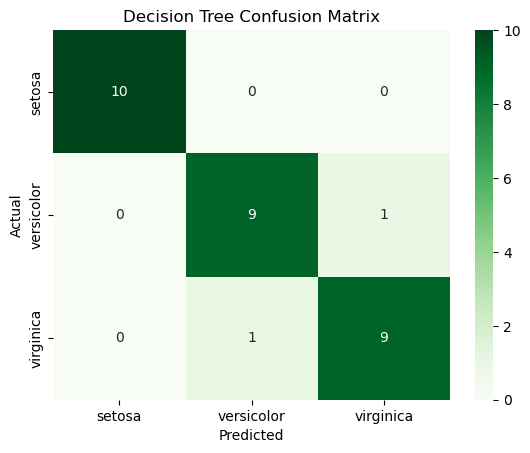

In [30]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens',xticklabels=class_names,yticklabels=class_names)
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [32]:
x_train_2d = x_train[['petal_length', 'petal_width']]

In [33]:
scaler_2d = StandardScaler()

x_train_2d_scaled = scaler_2d.fit_transform(x_train_2d)

lr_2d = LogisticRegression()
lr_2d.fit(x_train_2d_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [34]:
dt_2d = DecisionTreeClassifier(random_state=42)
dt_2d.fit(x_train_2d, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [35]:
x_min, x_max = x_train_2d.iloc[:, 0].min() - 0.5, x_train_2d.iloc[:, 0].max() + 0.5
y_min, y_max = x_train_2d.iloc[:, 1].min() - 0.5, x_train_2d.iloc[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

grid = np.c_[xx.ravel(), yy.ravel()]

lr_predictions = lr_2d.predict(scaler_2d.transform(grid))
dt_predictions = dt_2d.predict(grid)

classes = sorted(y.unique())
class_map = {label: i for i, label in enumerate(classes)}

lr_predictions = np.array([class_map[v] for v in lr_predictions]).reshape(xx.shape)
dt_predictions = np.array([class_map[v] for v in dt_predictions]).reshape(xx.shape)

y_train_encoded = y_train.map(class_map)

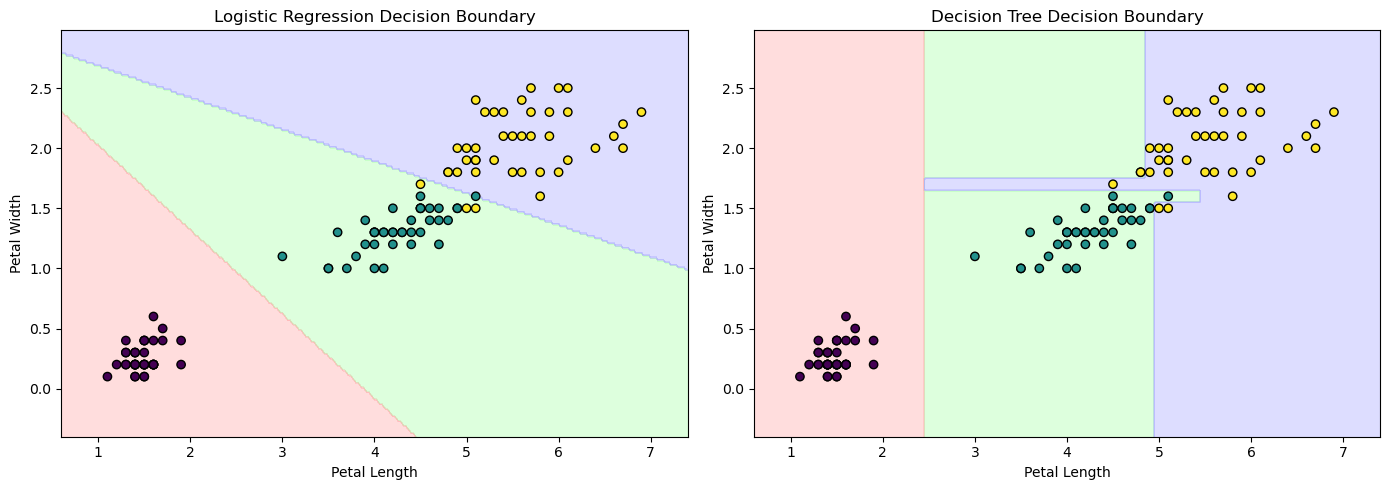

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cmap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])

# Logistic Regression
axes[0].contourf(xx, yy, lr_predictions, alpha=0.4, cmap=cmap)
axes[0].scatter(
    x_train_2d['petal_length'],
    x_train_2d['petal_width'],
    c=y_train_encoded,
    cmap='viridis',
    edgecolor='black'
)
axes[0].set_title("Logistic Regression Decision Boundary")
axes[0].set_xlabel("Petal Length")
axes[0].set_ylabel("Petal Width")

# Decision Tree
axes[1].contourf(xx, yy, dt_predictions, alpha=0.4, cmap=cmap)
axes[1].scatter(
    x_train_2d['petal_length'],
    x_train_2d['petal_width'],
    c=y_train_encoded,
    cmap='viridis',
    edgecolor='black'
)
axes[1].set_title("Decision Tree Decision Boundary")
axes[1].set_xlabel("Petal Length")
axes[1].set_ylabel("Petal Width")

plt.tight_layout()
plt.show()

In [37]:
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr, average='macro'),
        precision_score(y_test, y_pred_dt, average='macro')
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr, average='macro'),
        recall_score(y_test, y_pred_dt, average='macro')
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr, average='macro'),
        f1_score(y_test, y_pred_dt, average='macro')
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,Decision Tree,0.933333,0.933333,0.933333,0.933333



## Conclusion

In this project, I implemented two supervised
classification algorithms using the Iris dataset.

- Logistic Regression achieved 93.33% accuracy.
- Decision Tree achieved 93.33% accuracy.
- Both models achieved identical Precision, Recall,
  and F1-scores.
- Both models made identical predictions on the
  test dataset.

Both models performed equally on this particular
train-test split. Further testing with different
splits would be needed to determine which model
generalizes better.
